# 📊 **Regresión Lineal Simple y Múltiple con California Housing**

En este notebook vamos a trabajar con el dataset **California Housing**, disponible en `scikit-learn`.  
El objetivo es **aplicar regresión lineal simple y múltiple** para predecir el valor medio de las viviendas en distintas áreas de California.

### 🔎 **Contenido**

1. **Importación de librerías**  
   Se cargan todas las librerías necesarias para análisis, modelado, evaluación y visualización.

2. **Carga del dataset**  
   Usamos `fetch_california_housing(as_frame=True)`, que nos devuelve un objeto tipo *Bunch* con los datos en un DataFrame (`.frame`) y la variable objetivo (`.target`).

3. **Exploración de datos (EDA breve)**  
   - Dimensiones del dataset.  
   - Primeras filas.  
   - Estadísticas descriptivas.  
   - Correlación de las variables predictoras con la variable objetivo.  

4. **Regresión Lineal Simple**  
   - Seleccionamos solo una variable predictora (`MedInc`, ingreso medio).  
   - Entrenamos el modelo y evaluamos con métricas (`MSE`, `R²`).  
   - Visualizamos la recta de regresión ajustada sobre los datos de prueba.  

5. **Regresión Lineal Múltiple**  
   - Usamos **todas las variables predictoras** disponibles en el dataset.  
   - Entrenamos el modelo, obtenemos métricas y coeficientes.  
   - Graficamos valores reales vs valores predichos para evaluar el ajuste.


### **Importación de librerías**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

### **Carga del dataset**

`fetch_california_housing(as_frame=True)` devuelve un objeto tipo **Bunch**, que contiene:

* **`frame`**: un `DataFrame` con las variables predictoras (X).  
* **`target`**: una serie/columna objetivo (y), llamada `MedHouseVal`.  

**Nota:** el parámetro `as_frame=True` indica que los datos deben entregarse directamente como un `pandas.DataFrame`.  
Si no se incluye, el método devuelve arreglos de `NumPy`, lo que puede ser menos práctico para la exploración y manipulación inicial de los datos.  

In [ ]:
data = fetch_california_housing(as_frame=True)
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [ ]:
data['target']

,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422
...,...
20635,0.781
20636,0.771
20637,0.923
20638,0.847


In [ ]:
df = data.frame.copy()

# Nota: usamos .copy() para crear un DataFrame independiente del original (data.frame).
# Si hacemos df = data.frame, ambos apuntan al mismo objeto en memoria.
# Entonces, cualquier cambio en df (ej. añadir o eliminar columnas) también afectaría a data.frame.
# Con .copy() evitamos este "aliasing" y trabajamos con una copia segura.

df["MedHouseVal"] = data.target  # añadimos la variable objetivo explícitamente
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# Nombres de columnas (features) y objetivo
feature_names = data.feature_names
target_name = "MedHouseVal"

### **Exploratory Data Analysis (EDA)**

In [ ]:
print(f"Dimensiones del DataFrame: {df.shape}")
print("\nPrimeras filas:")
df.head()

Dimensiones del DataFrame: (20640, 9)

Primeras filas:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
print("\nDescripción estadística de features (X):")
df[feature_names].describe()


Descripción estadística de features (X):


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [ ]:
print("\nDescripción estadística de la variable objetivo (y):")
df[[target_name]].describe()


Descripción estadística de la variable objetivo (y):


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


In [ ]:
# Revisión rápida de valores faltantes
print("\nConteo de valores faltantes por columna:")
df.isna().sum()


Conteo de valores faltantes por columna:


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
# Correlación de features con el objetivo
print("\nCorrelación (Pearson) de cada feature con el objetivo:")
corr_with_target = df[feature_names].corrwith(df[target_name]).sort_values(ascending=False)
corr_with_target


Correlación (Pearson) de cada feature con el objetivo:


,0
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


$$\beta = (X^T X)^{-1} X^T y$$

In [ ]:
X = np.array([[1, mi] for mi in df['MedInc']])
y = np.array(df['MedHouseVal'])

beta = np.linalg.inv(X.T @ X) @ X.T @ y
beta

array([0.45085577, 0.41793849])

In [ ]:
X

array([[1.    , 8.3252],
       [1.    , 8.3014],
       [1.    , 7.2574],
       ...,
       [1.    , 1.7   ],
       [1.    , 1.8672],
       [1.    , 2.3886]])

In [ ]:
beta[1], beta[0]

(np.float64(0.41793849201896266), np.float64(0.45085576703267943))

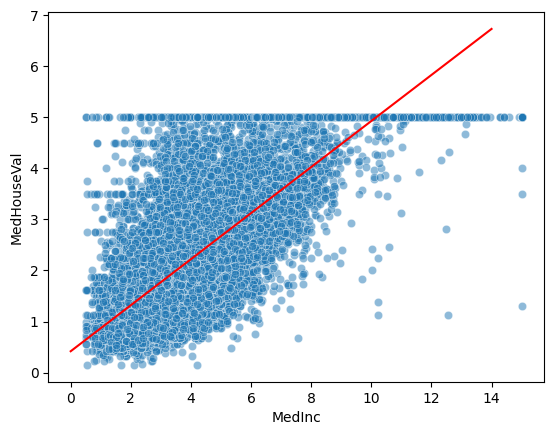

In [ ]:
sns.scatterplot(data = df, x = 'MedInc', y = 'MedHouseVal', alpha = 0.5)
x = np.arange(0, 15)
y = beta[0] * x + beta[1] # y = mx + b
plt.plot(x, y, color = 'red')

### **Regresión Lineal Simple**

Esamos una sola variable (MedInc) -> y

In [ ]:
# Elección de la feature: MedInc
X_simple = df[["MedInc"]]

# Asignación de la variable objetivo
y = df[target_name]

In [ ]:
# Dividimos en entrenamiento y prueba para evaluar generalización
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

In [ ]:
# Creamos y entrenamos el modelo de regresión lineal
lr_simple = LinearRegression()
lr_simple.fit(X_train_s, y_train_s) # Entrenamiento

LinearRegression()

In [ ]:
X_test_s

,MedInc
20046,1.6812
3024,2.5313
15663,3.4801
20484,5.7376
9814,3.7250
...,...
15362,4.6050
16623,2.7266
18086,9.2298
2144,2.7850


In [ ]:
# Predicciones en test
y_pred_s = lr_simple.predict(X_test_s)
y_pred_s

array([1.14958917, 1.50606882, 1.90393718, ..., 4.31500772, 1.612455  ,
       1.93412956])

#### **Evaluación y visualización**

$$MSE = \frac{\sum_i e^2}{n}$$

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}}$$

$$SS_{tot} = \sum_i e^2$$
$$SS_{res} = \sum_i (y_i - \bar{y})^2$$

In [ ]:
np.sum((y - np.mean(y)) ** 2)

np.float64(27483.19819368851)

In [ ]:
# Métricas de evaluación en test
mse_s = mean_squared_error(y_test_s, y_pred_s) # Error cuadratico medio
r2_s = r2_score(y_test_s, y_pred_s) # Coeficiente de determinación

In [ ]:
print(f"Intercepto: {lr_simple.intercept_}")
print(f"Coeficiente (MedInc): {lr_simple.coef_[0]}")
print(f"MSE (test): {mse_s:.4f}")
print(f"R^2 (test): {r2_s:.4f}")

Intercepto: 0.4445972916907879
Coeficiente (MedInc): 0.4193384939381271
MSE (test): 0.7091
R^2 (test): 0.4589


In [ ]:
order_idx = np.argsort(X_test_s.values.squeeze()) # para dibujar la recta sobre el scatter, ordenamos por X_test_s
X_plot = X_test_s.values.squeeze()[order_idx]
y_plot = y_test_s.values.squeeze()[order_idx]
y_pred_plot = y_pred_s.squeeze()[order_idx]

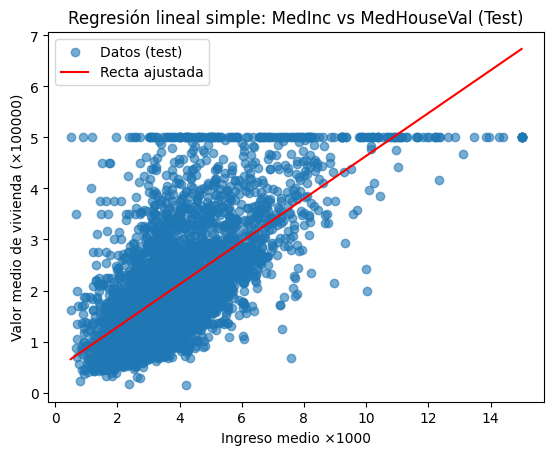

In [ ]:
plt.figure()
plt.scatter(X_test_s, y_test_s, alpha=0.6, label="Datos (test)")
plt.plot(X_plot, y_pred_plot, label="Recta ajustada", color = 'red')
plt.title("Regresión lineal simple: MedInc vs MedHouseVal (Test)")
plt.xlabel("Ingreso medio ×1000")
plt.ylabel("Valor medio de vivienda (×100000)")
plt.legend()
plt.show()

### **Regresión Lineal Múltiple**

In [ ]:
df[['MedInc', 'HouseAge']]

,MedInc,HouseAge
0,8.3252,41.0
1,8.3014,21.0
2,7.2574,52.0
3,5.6431,52.0
4,3.8462,52.0
...,...,...
20635,1.5603,25.0
20636,2.5568,18.0
20637,1.7000,17.0
20638,1.8672,18.0


In [ ]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [ ]:
X = df[feature_names]

# Dividimos en entrenamiento y prueba
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# Creamos y entrenamos el modelo de regresión lineal múltiple
lr_multi = LinearRegression()
lr_multi.fit(X_train_m, y_train_m)

LinearRegression()

In [ ]:
# Predicciones en test
y_pred_m = lr_multi.predict(X_test_m)

In [ ]:
y_pred_m

array([0.71912284, 1.76401657, 2.70965883, ..., 4.46877017, 1.18751119,
       2.00940251])

#### **Evaluación y visualización**

In [ ]:
# Métricas de evaluación en test
mse_m = mean_squared_error(y_test_m, y_pred_m)
r2_m = r2_score(y_test_m, y_pred_m)

In [ ]:
print(f"Intercepto: {lr_multi.intercept_}")
print(f"MSE (test): {mse_m:.4f}")
print(f"R^2 (test): {r2_m:.4f}")

Intercepto: -37.02327770606409
MSE (test): 0.5559
R^2 (test): 0.5758


In [ ]:
# Coeficientes por variable (útil para interpretar dirección e importancia relativa)
coefs_df = pd.DataFrame({
    "feature": feature_names,
    "coef": lr_multi.coef_
})

coefs_df

,feature,coef
0,MedInc,0.448675
1,HouseAge,0.009724
2,AveRooms,-0.123323
3,AveBedrms,0.783145
4,Population,-0.000002
5,AveOccup,-0.003526
6,Latitude,-0.419792
7,Longitude,-0.433708


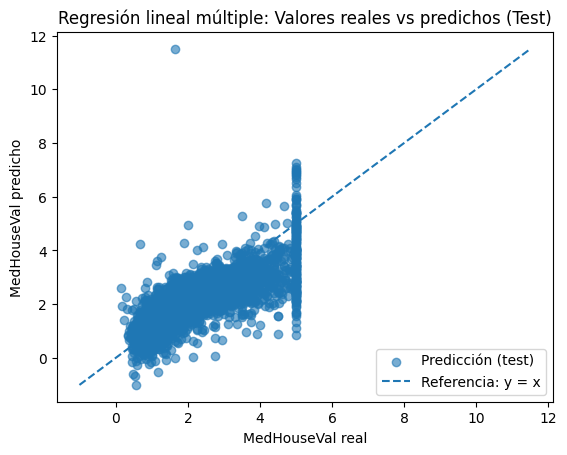

In [ ]:
# Visualización: y real vs y predicho en test (línea y=x como referencia ideal)
plt.figure()
plt.scatter(y_test_m, y_pred_m, alpha=0.6, label="Predicción (test)")
min_y = min(y_test_m.min(), y_pred_m.min())
max_y = max(y_test_m.max(), y_pred_m.max())
plt.plot([min_y, max_y], [min_y, max_y], linestyle="--", label="Referencia: y = x")
plt.title("Regresión lineal múltiple: Valores reales vs predichos (Test)")
plt.xlabel("MedHouseVal real")
plt.ylabel("MedHouseVal predicho")
plt.legend()
plt.show()